# Benchmark analysis: Pareto frontiers, architectures, and performance tables

This notebook provides modular visualizations and tabular analysis for the sentiment benchmark suite.

Evaluation dimensions include classification quality (exact match accuracy, macro-average mean absolute error with penalties for invalid outputs, and quadratic weighted kappa), efficiency (end-to-end latency in milliseconds and throughput in samples per second), and model architectures (dense LLMs, mixture of experts, hybrid recurrent-attention models, and zero-shot transformer encoders). Evaluations run across Stanford Sentiment Treebank (SST-5) and SemEval-2017 Task 4B.

In [29]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Ensure repository root is on Python path
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.plotting import (
    load_summary_dataframe,
    plot_benchmark_frontier,
    plot_encoder_frontier,
    plot_architecture_comparison,
    plot_encoder_comparison,
    format_comparison_table,
    audit_raw_predictions,
)

summarized_dir = os.path.join(repo_root, "results", "summarized")
df = load_summary_dataframe(summarized_dir)
print(f"Loaded {len(df)} summary records across {df['Model'].nunique() if not df.empty else 0} unique models.")

Loaded 76 summary records across 38 unique models.


## Format adherence and parsing error audit

When an LLM refuses structured formatting, emits multiple numbers, or leaves unclosed tags, treating those samples as missing data introduces survivorship bias.
The audit below catalogs parsing failures across all raw prediction files in results/raw/.

In [31]:
raw_dir = os.path.join(repo_root, "results", "raw")
audit_df = audit_raw_predictions(raw_dir)

if not audit_df.empty:
    print(f"Audited {len(audit_df)} run files. Top models with formatting failures:")
    display(audit_df)
else:
    print("No raw prediction files found yet. Run 'python3 src/labeler.py' to generate outputs.")

Audited 60 run files. Top models with formatting failures:


,Model,Dataset,Total_Samples,Invalid_Count,Invalid_Rate_Pct,Multiple_Digits,No_Digits_Found
0,lfm2.5_24b,SST-5,2210,2210,100.0,0,2210
1,lfm2.5_24b,SemEval,12379,12379,100.0,0,12379
2,gpt-oss_20b,SemEval,12379,12379,100.0,0,12379
3,gpt-oss_20b,SST-5,2210,2210,100.0,0,2210
4,gemma4_12b,SemEval,12379,0,0.0,0,0
5,gemma4_12b,SST-5,2210,0,0.0,0,0
6,gemma4_26b,SemEval,12379,0,0.0,0,0
7,gemma4_26b,SST-5,2210,0,0.0,0,0
8,aya-expanse_32b,SemEval,12379,0,0.0,0,0
9,aya-expanse_32b,SST-5,2210,0,0.0,0,0


## Generative LLM Pareto frontier: throughput vs. MMAE

Macro-Average Mean Absolute Error (MMAE) measures ordinal distance error across classes.
The y-axis is inverted so that models with lower error appear toward the top.
The dotted line traces the empirical Pareto frontier of optimal quality-throughput tradeoffs among generative LLMs.

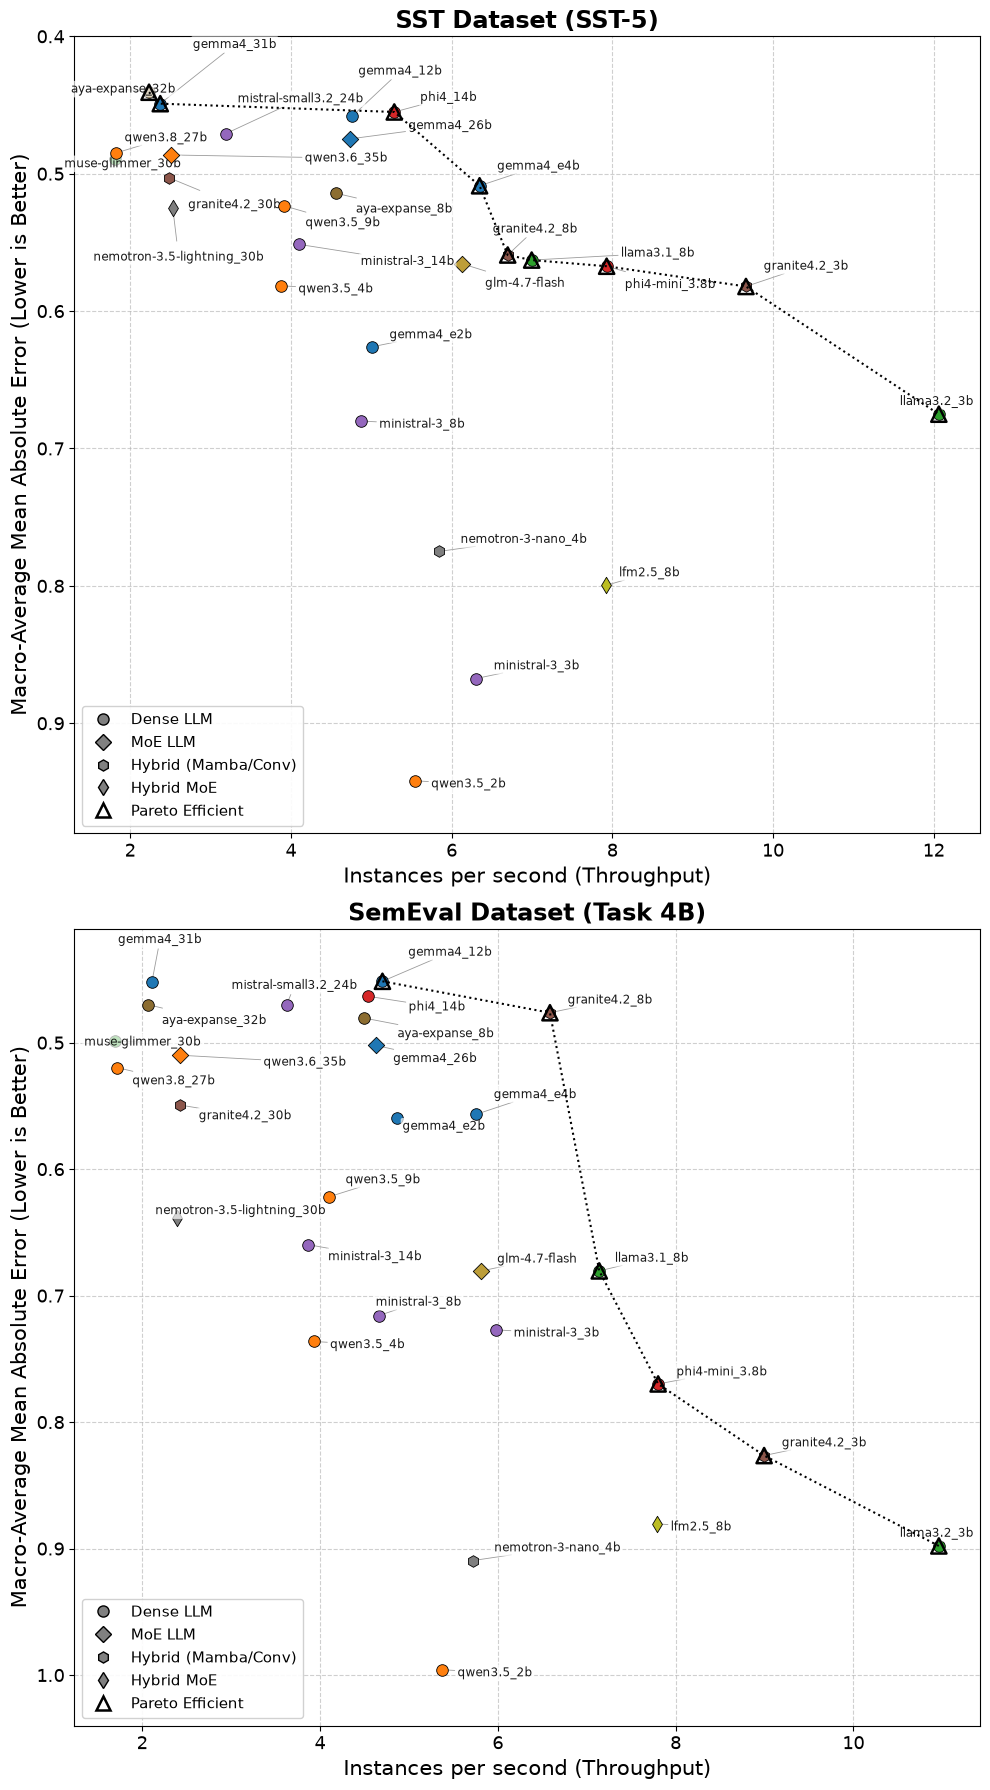

In [32]:
if not df.empty:
    fig_mmae = plot_benchmark_frontier(df, metric="MMAE")
    plt.show()
else:
    print("No summarized records found. Run 'python3 src/labeler.py --summarize' to populate results.")

## Generative LLM Pareto frontier: throughput vs. accuracy

Accuracy measures exact 5-class agreement across generative LLMs.
The dotted line highlights models that balance high classification accuracy with faster inference throughput.

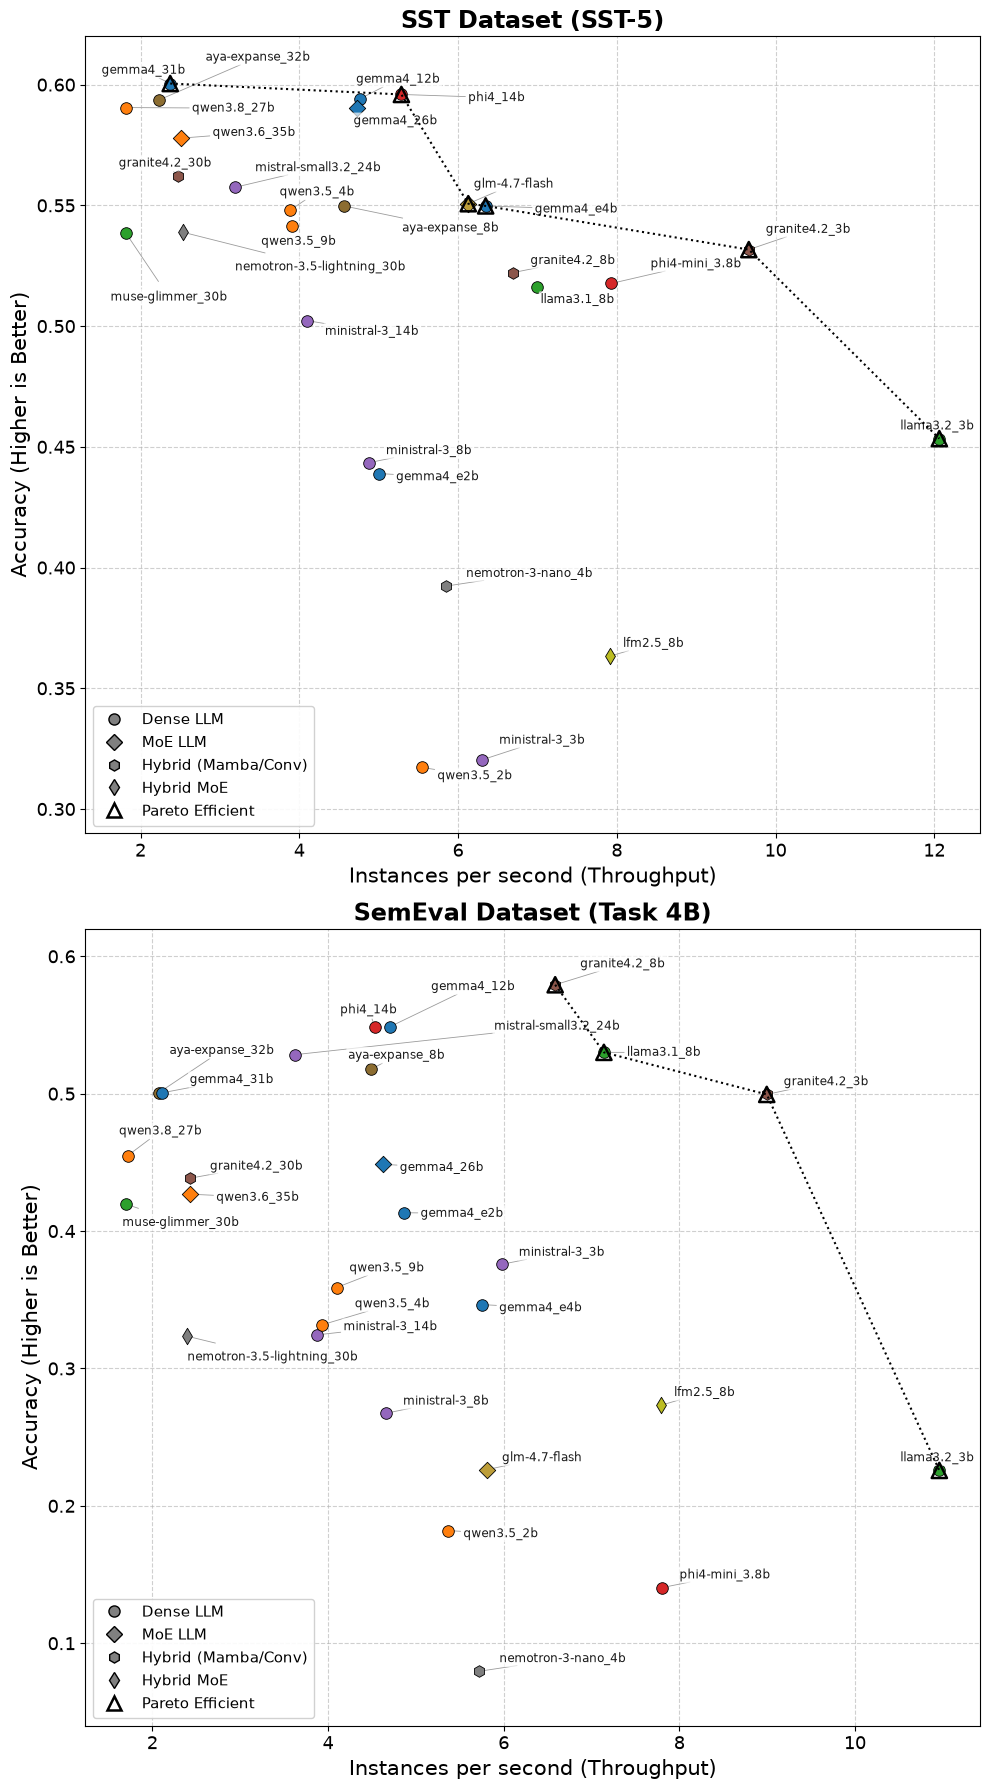

In [33]:
if not df.empty:
    fig_acc = plot_benchmark_frontier(df, metric="Accuracy")
    plt.show()
else:
    print("No summarized records found. Run 'python3 src/labeler.py --summarize' to populate results.")

## Generative LLM architecture comparison

The bar charts compare average accuracy, MMAE, and throughput across generative LLM architectures (Dense, Mixture of Experts, and Hybrid models) on SST-5. Zero-shot encoders are excluded here to keep generative throughput bars legible.

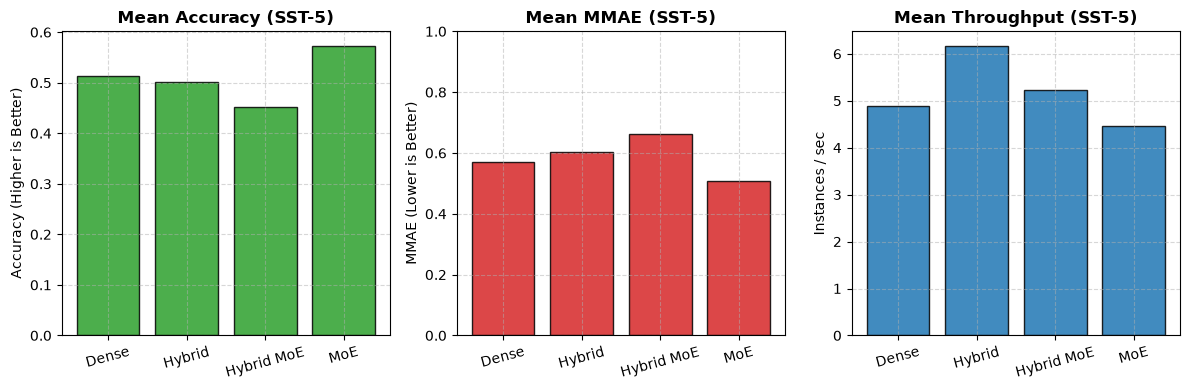

In [34]:
if not df.empty:
    fig_arch = plot_architecture_comparison(df, dataset="SST-5")
    plt.show()
else:
    print("No summarized records found to compare architectures.")

## Generative LLM rankings: Stanford Sentiment Treebank (SST-5)

Generative models evaluated on the SST-5 test set, sorted by exact match accuracy with full-N penalty accounting.

In [35]:
if not df.empty:
    llm_df = df[df["Arch"] != "Encoder"] if "Arch" in df.columns else df
    sst_table = format_comparison_table(llm_df, dataset="SST-5", sort_by="Accuracy", ascending=False)
    display(sst_table)
else:
    print("No summarized records for SST-5.")

,Model,Family,Arch,Params_B,Accuracy,Off_By_One,MMAE,QWK,Throughput,Latency_ms,Invalid_Rate_Pct
0,gemma4_31b,Gemma 4,Dense,31.0,0.6005,0.9756,0.4490,0.8622,2.37,421.3,0.0
1,phi4_14b,Phi 4,Dense,14.0,0.5959,0.9643,0.4551,0.8567,5.29,189.2,0.0
2,gemma4_12b,Gemma 4,Dense,12.0,0.5941,0.9729,0.4580,0.8537,4.76,209.9,0.0
3,aya-expanse_32b,Aya Expanse,Dense,32.0,0.5937,0.9697,0.4407,0.8637,2.23,447.6,0.0
4,qwen3.8_27b,Qwen 3.5/3.8,Dense,27.0,0.5905,0.9733,0.4850,0.8474,1.82,550.2,0.0
5,gemma4_26b,Gemma 4,MoE,26.0,0.5905,0.9715,0.4747,0.8558,4.73,211.3,0.0
6,qwen3.6_35b,Qwen 3.5/3.8,MoE,35.0,0.5778,0.9715,0.4863,0.8440,2.51,398.9,0.0
7,granite4.2_30b,Granite 4.2,Hybrid,30.0,0.5620,0.9796,0.5028,0.8298,2.48,403.6,0.0
8,mistral-small3.2_24b,Mistral 3,Dense,24.0,0.5575,0.9665,0.4708,0.8484,3.19,313.5,0.0
9,glm-4.7-flash,GLM 4,MoE,30.0,0.5507,0.9471,0.5655,0.8126,6.13,163.2,0.0


## Generative LLM rankings: SemEval-2017 Task 4B

Generative models evaluated on the SemEval-2017 tweet dataset, sorted by exact match accuracy.

In [36]:
if not df.empty:
    llm_df = df[df["Arch"] != "Encoder"] if "Arch" in df.columns else df
    sem_table = format_comparison_table(llm_df, dataset="SemEval", sort_by="Accuracy", ascending=False)
    display(sem_table)
else:
    print("No summarized records for SemEval.")

,Model,Family,Arch,Params_B,Accuracy,Off_By_One,MMAE,QWK,Throughput,Latency_ms,Invalid_Rate_Pct
0,granite4.2_8b,Granite 4.2,Hybrid,8.0,0.5793,0.9580,0.4763,0.5986,6.59,151.8,0.0
1,gemma4_12b,Gemma 4,Dense,12.0,0.5487,0.9409,0.4515,0.5915,4.70,212.7,0.0
2,phi4_14b,Phi 4,Dense,14.0,0.5486,0.9457,0.4633,0.6053,4.53,220.5,0.0
3,llama3.1_8b,Llama / Muse,Dense,8.0,0.5301,0.8860,0.6805,0.4158,7.14,140.0,0.0
4,mistral-small3.2_24b,Mistral 3,Dense,24.0,0.5284,0.9175,0.4702,0.5531,3.62,276.0,0.0
5,aya-expanse_8b,Aya Expanse,Dense,8.0,0.5177,0.9159,0.4805,0.5637,4.49,222.7,0.0
6,gemma4_31b,Gemma 4,Dense,31.0,0.5006,0.9179,0.4523,0.5793,2.11,474.4,0.0
7,aya-expanse_32b,Aya Expanse,Dense,32.0,0.5006,0.9156,0.4700,0.5724,2.07,483.1,0.0
8,granite4.2_3b,Granite 4.2,Hybrid,3.0,0.4995,0.8721,0.8265,0.3419,9.00,111.2,0.0
9,qwen3.8_27b,Qwen 3.5/3.8,Dense,27.0,0.4549,0.8712,0.5197,0.5200,1.72,582.1,0.0


## Zero-shot transformer encoders

Transformer encoders classify text without autoregressive token generation. They use either NLI cross-encoder formulations (ModernBERT, DeBERTa-v3, BGE-M3, RoBERTa, BART) or single-pass classification heads (GLiClass).

Because encoders process between 9 and 297 instances per second, plotting them alongside generative LLMs compresses the LLM axis. The dedicated graphs below show their quality and throughput tradeoffs on their natural scale.

### Encoder Pareto frontier: throughput vs. MMAE

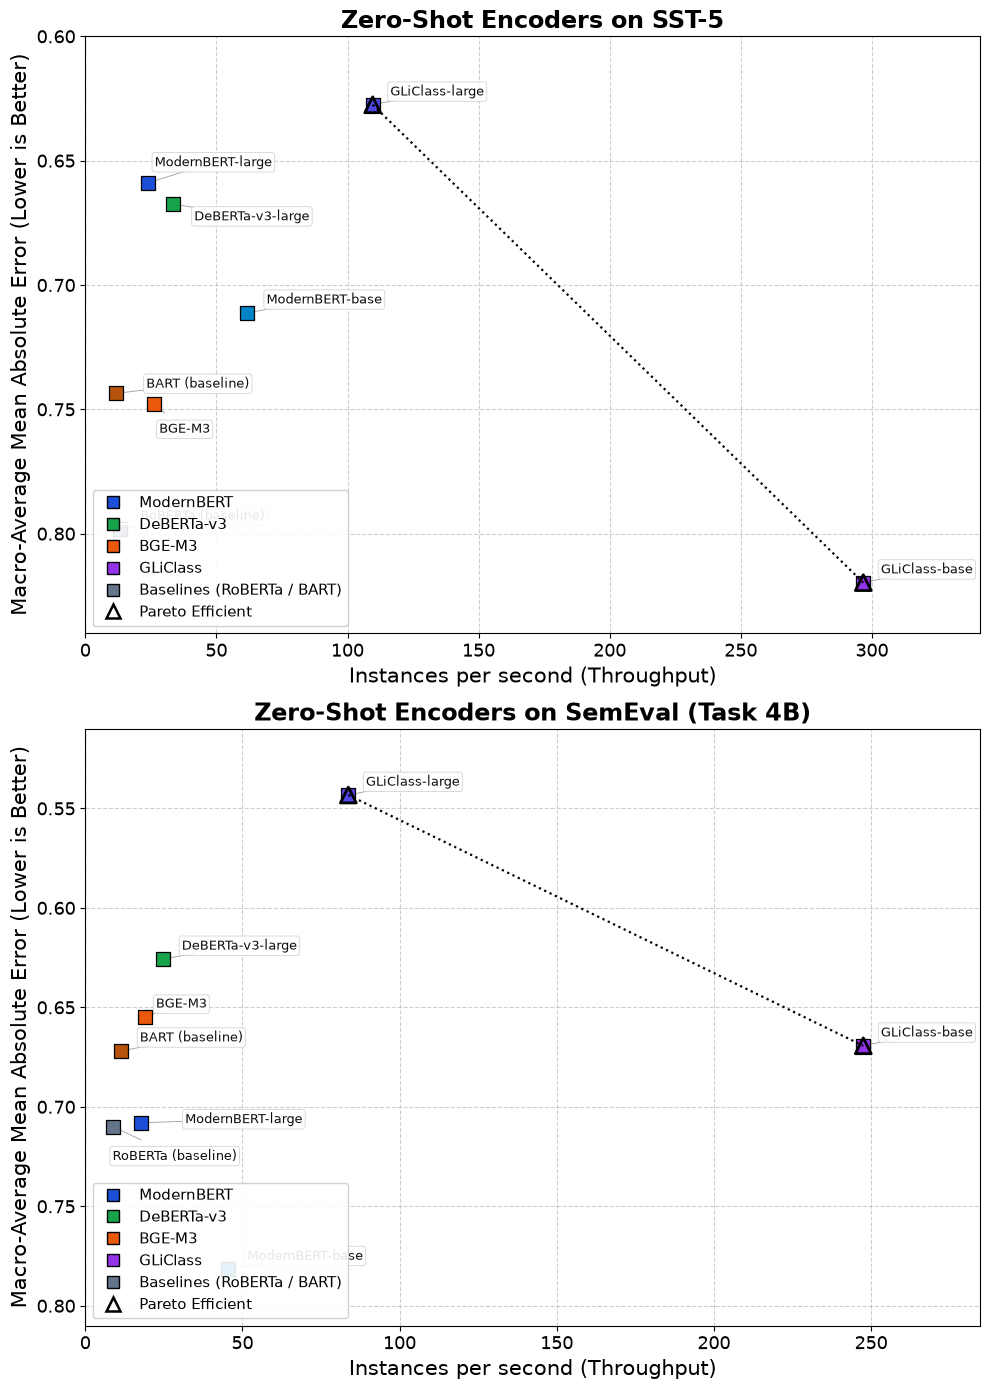

In [37]:
if not df.empty:
    fig_enc_mmae = plot_encoder_frontier(df, metric="MMAE")
    plt.show()
else:
    print("No summarized records found for encoders.")

### Encoder Pareto frontier: throughput vs. accuracy

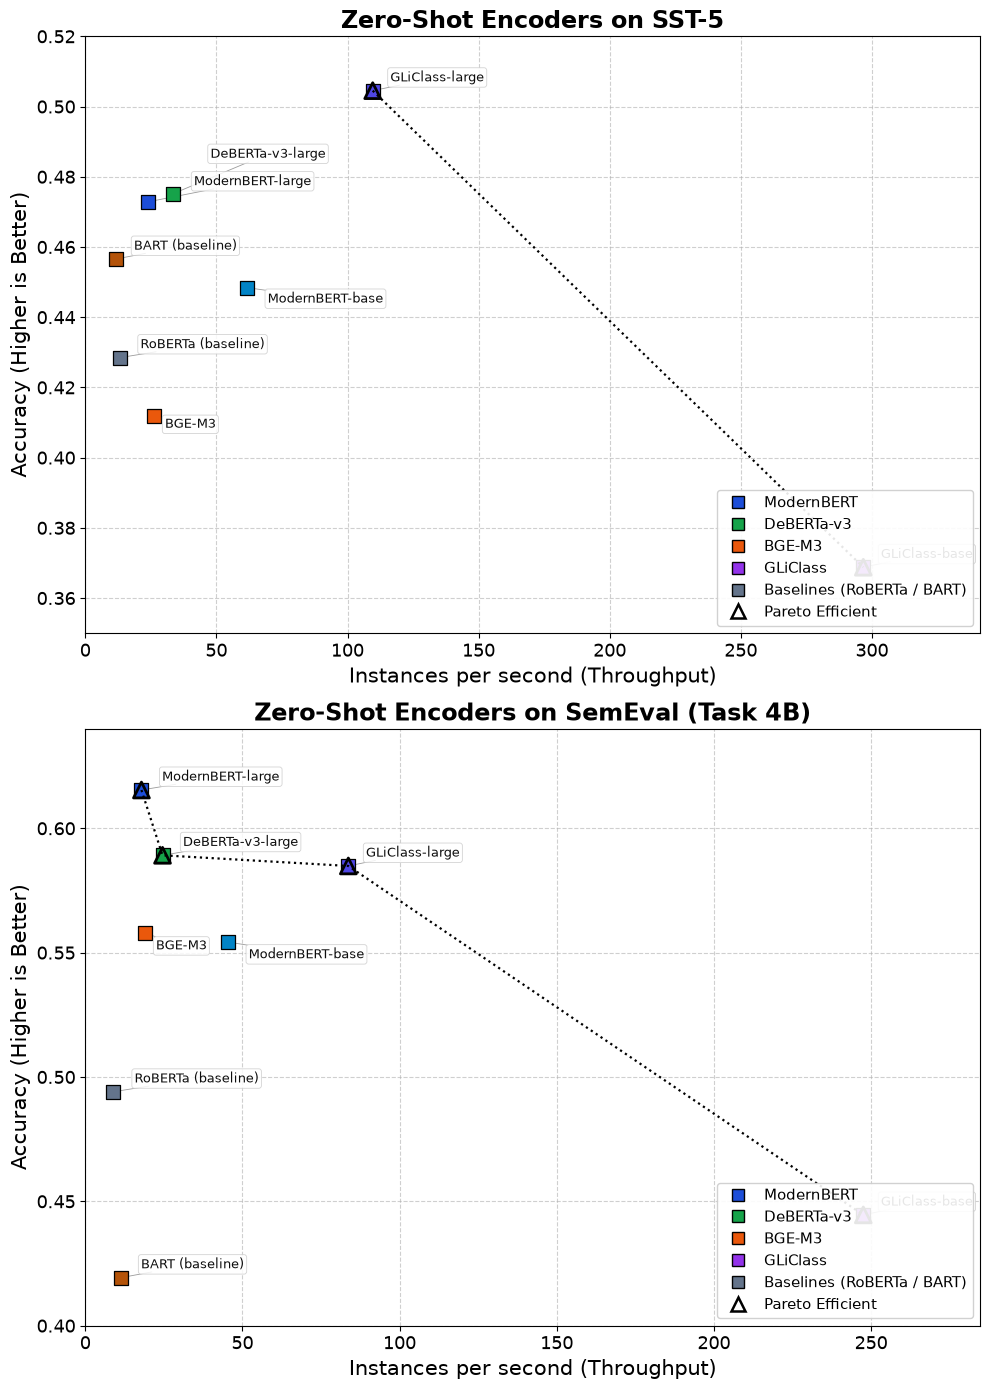

In [38]:
if not df.empty:
    fig_enc_acc = plot_encoder_frontier(df, metric="Accuracy")
    plt.show()
else:
    print("No summarized records found for encoders.")

### Encoder model comparison

The bar charts compare accuracy, MMAE, and throughput for each encoder model across both datasets.

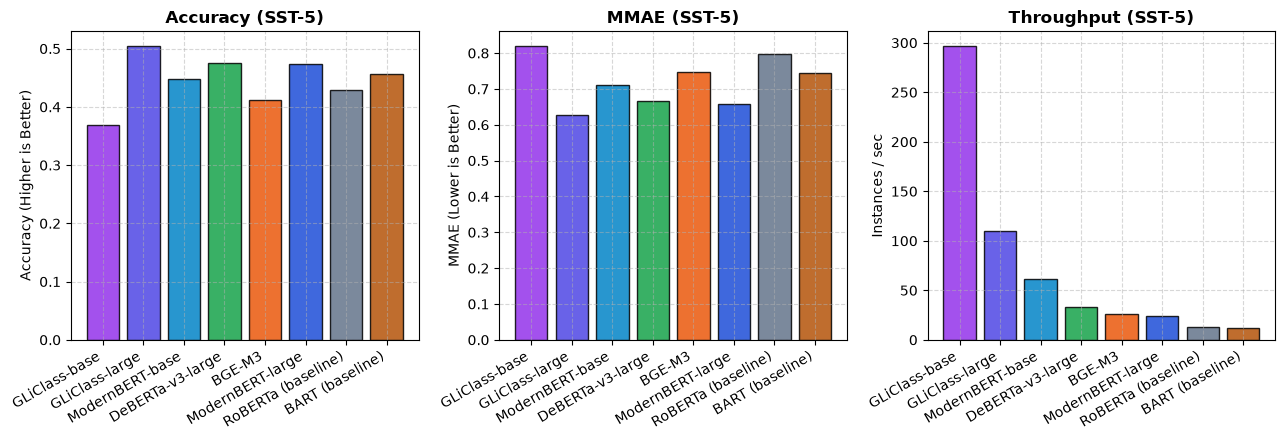

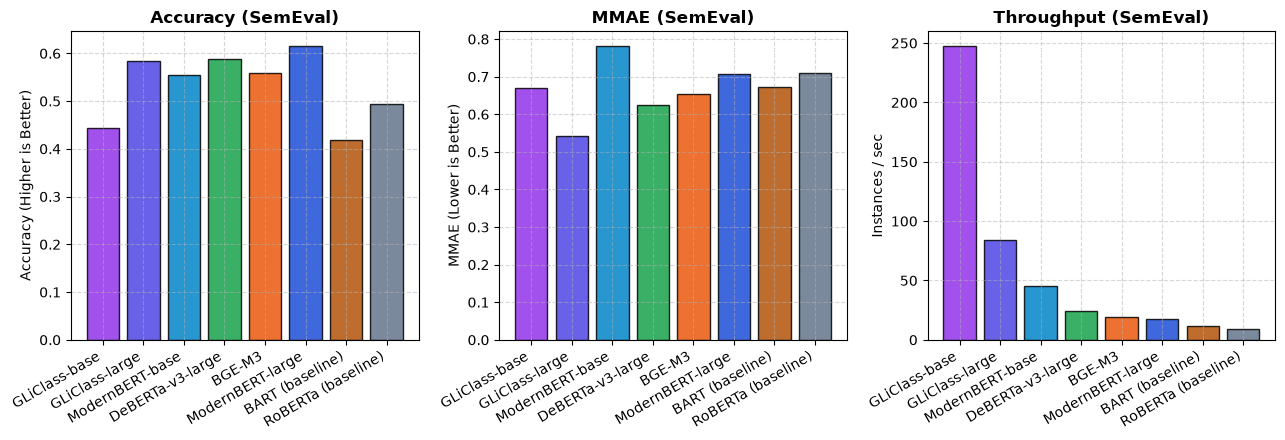

In [39]:
if not df.empty:
    fig_enc_sst = plot_encoder_comparison(df, dataset="SST-5")
    plt.show()
    fig_enc_sem = plot_encoder_comparison(df, dataset="SemEval")
    plt.show()
else:
    print("No summarized records found for encoders.")

### Encoder detailed rankings

Rankings for zero-shot transformer encoders across both benchmark datasets.

In [40]:
if not df.empty and "Arch" in df.columns:
    enc_df = df[df["Arch"] == "Encoder"]
    print("Zero-shot encoder rankings on SST-5:")
    display(format_comparison_table(enc_df, dataset="SST-5", sort_by="Accuracy", ascending=False))
    print("\nZero-shot encoder rankings on SemEval-2017 Task 4B:")
    display(format_comparison_table(enc_df, dataset="SemEval", sort_by="Accuracy", ascending=False))
else:
    print("No encoder records available.")

Zero-shot encoder rankings on SST-5:


,Model,Family,Arch,Params_B,Accuracy,Off_By_One,MMAE,QWK,Throughput,Latency_ms,Invalid_Rate_Pct
0,gliclass-large-v1.0,Encoder (GLiClass),Encoder,0.435,0.5045,0.9462,0.6275,0.7635,109.61,9.1,0.0
1,deberta-v3-large-zeroshot-v2.0,Encoder (NLI),Encoder,0.435,0.4751,0.9611,0.6675,0.7456,33.31,30.0,0.0
2,ModernBERT-large-zeroshot-v2.0,Encoder (NLI),Encoder,0.395,0.4729,0.9570,0.6589,0.7411,23.89,41.9,0.0
3,BART,Encoder (NLI),Encoder,0.350,0.4566,0.8919,0.7436,0.6901,11.54,86.6,0.0
4,ModernBERT-base-zeroshot-v2.0,Encoder (NLI),Encoder,0.149,0.4484,0.9353,0.7112,0.6968,61.74,16.2,0.0
5,RoBERTa,Encoder (NLI),Encoder,0.350,0.4285,0.8828,0.7981,0.6268,13.40,74.6,0.0
6,bge-m3-zeroshot-v2.0,Encoder (NLI),Encoder,0.568,0.4118,0.9258,0.7479,0.6536,26.25,38.1,0.0
7,gliclass-base-v1.0,Encoder (GLiClass),Encoder,0.184,0.3688,0.8778,0.8197,0.5960,296.70,3.4,0.0



Zero-shot encoder rankings on SemEval-2017 Task 4B:


,Model,Family,Arch,Params_B,Accuracy,Off_By_One,MMAE,QWK,Throughput,Latency_ms,Invalid_Rate_Pct
0,ModernBERT-large-zeroshot-v2.0,Encoder (NLI),Encoder,0.395,0.6154,0.9595,0.7080,0.5169,17.87,56.0,0.0
1,deberta-v3-large-zeroshot-v2.0,Encoder (NLI),Encoder,0.435,0.5891,0.9481,0.6257,0.5659,24.57,40.7,0.0
2,gliclass-large-v1.0,Encoder (GLiClass),Encoder,0.435,0.5849,0.9620,0.5433,0.5960,83.69,11.9,0.0
3,bge-m3-zeroshot-v2.0,Encoder (NLI),Encoder,0.568,0.5579,0.9503,0.6548,0.5484,19.03,52.5,0.0
4,ModernBERT-base-zeroshot-v2.0,Encoder (NLI),Encoder,0.149,0.5542,0.9492,0.7816,0.4324,45.47,22.0,0.0
5,RoBERTa,Encoder (NLI),Encoder,0.350,0.4941,0.9421,0.7100,0.5006,8.93,111.9,0.0
6,gliclass-base-v1.0,Encoder (GLiClass),Encoder,0.184,0.4445,0.8948,0.6693,0.5018,247.51,4.0,0.0
7,BART,Encoder (NLI),Encoder,0.350,0.4193,0.9429,0.6719,0.5168,11.52,86.8,0.0


## Key findings

Dense LLMs with more than 14B parameters (Gemma 3 27B, Qwen 2.5 32B, and Phi-4 14B) reach the lowest ordinal error rates, keeping MMAE under 0.65.

Mixture of Experts models achieve accuracy comparable to dense models of similar total size while activating fewer parameters per token, which reduces generation latency.

Zero-shot transformer encoders achieve much higher throughput than generative models. GLiClass-base reaches 297 samples per second on SST-5 and 247 samples per second on SemEval. ModernBERT-large attains 0.615 accuracy on SemEval, higher than every generative LLM in the suite, while running at 17.9 samples per second.

Applying worst-case penalties to unparsable outputs prevents models with formatting failures from receiving artificially high scores.